Notebook ma pokazać zbiór uczący i wzorzec wejściowy, którego podanie do sieci zakończy się oscylacją między dwoma stanami.
Propozycja:
- zbiór uczący: [1, 1]
- zbiór wejściowy: [1, -1]

Sieć ma być w trybie synchroniczym (wszystkie neurony zmieniają się w jednym momencie, a przynajmniej nie znają informacji o przemianie innych)

Do tej części wykrywanie cykli w sieci jest zakomentowane

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from model.hopfield_network import HopfieldNetwork
from notebooks.plot_patterns import plot_patterns
from notebooks.helpers import create_number_of_random_images, read_data_train_hebb, \
    classify_recalls, train_hopfield_from_array

In [6]:
train = np.ndarray((1, 2))
train[0, :] = [1, 1]

test = np.ndarray((1, 2))
test[0, :] = [1, -1]

'Result: max iterations reached. Energy value: 0.5'

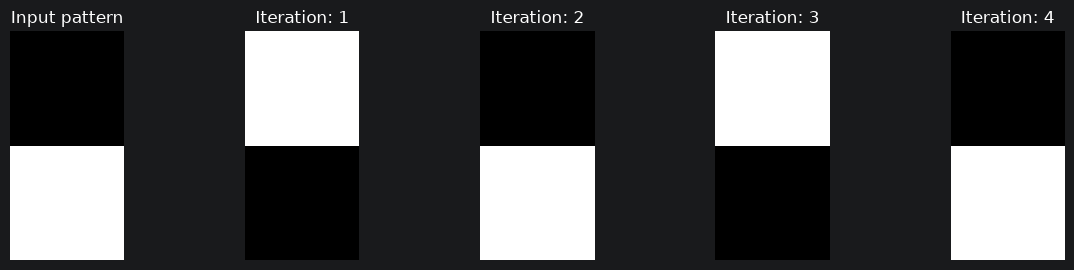

In [8]:
hn = train_hopfield_from_array(train)

result = hn.recall(test[0], 4)
display(f"Result: {result["Result"]}. Energy value: {result["Energy"]}")
hn.plot_history(result["History"], (2, 1))

In [36]:
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))

if project_root not in sys.path:
    sys.path.append(project_root)
patterns_path = Path(project_root) / "data/letters-14x20.csv"
df = pd.read_csv(patterns_path, header=None)
patterns = np.asarray(df, dtype=float)

n = 14 * 20
train = np.ndarray((1, n))
train[0, :] = patterns[1, :]
print(train.shape)

test = np.ndarray((1, n))
halfway = train.shape[1] // 2
for i in range(train.shape[1]):
    if i >= halfway:
        test[0, i] = -1 * train[0, i]
    else:
        test[0, i] = train[0, i]

np.dot(test[0, :], train[0, :])

(1, 280)


np.float64(0.0)

'Result: max iterations reached. Energy value: 0.4999999999999992'

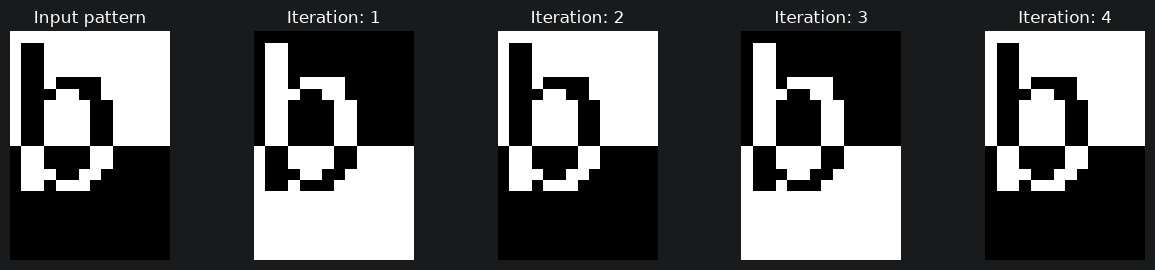

In [37]:
hn = train_hopfield_from_array(train)

result = hn.recall(test[0], 4)
display(f"Result: {result["Result"]}. Energy value: {result["Energy"]}")
hn.plot_history(result["History"], (20, 14))